# 02. Análise Exploratória e Inferência Estatística — Layoffs no Entretenimento Digital (2020–2026)

**Descrição:** Investigação estatística e visual dos dados processados e das views analíticas do PostgreSQL, validando hipóteses sobre assimetria distributiva, diferenças entre subsegmentos (`Consumer` vs. `Media`), severidade por estágio corporativo, concentração de Pareto e impacto geográfico, com exportação de gráficos em alta resolução (`docs/figures/`).

## Índice
<div style="line-height:1.5">

<span style="font-size:18px">**1.** Configuração de Ambiente, Paleta Visual e Carga de Dados</span><br>
   <span style="font-size:16px">&emsp;**1.1.** Impotes </span><br>
   <span style="font-size:16px">&emsp;**1.2.** Conexão ao PostgreSQL e Carregamento da Base e Views Analíticas</span><br>
<span style="font-size:18px">**2.** Estatística Descritiva Robusta e Testes de Normalidade</span><br>
   <span style="font-size:16px">&emsp;**2.1.** Métricas Paramétricas vs. Não-Paramétricas (Média, Mediana, IQR, Assimetria e Curtose)</span><br>
   <span style="font-size:16px">&emsp;**2.2.** Testes de Aderência à Normalidade (Shapiro-Wilk e D'Agostino $K^2$)</span><br>
<span style="font-size:18px">**3.** Dinâmica Temporal e Ciclos de Contração (2020–2026)</span><br>
   <span style="font-size:16px">&emsp;**3.1.** Evolução Anual e Trimestral por Subsegmento</span><br>
   <span style="font-size:16px">&emsp;**3.2.** Análise de Picos Críticos e Volatilidade Setorial</span><br>
<span style="font-size:18px">**4.** Testes de Hipótese e Comparação Estrutural</span><br>
   <span style="font-size:16px">&emsp;**4.1.** Comparação entre Subsegmentos (`Consumer` vs. `Media` — Mann-Whitney U e Welch's $t$)</span><br>
   <span style="font-size:16px">&emsp;**4.2.** Severidade por Estágio Corporativo (One-Way ANOVA, Kruskal-Wallis e Pós-Teste de Dunn/Tukey)</span><br>
   <span style="font-size:16px">&emsp;**4.3.** Correlação entre Captação de Recursos, Volume e Percentual de Corte (Spearman)</span><br>
<span style="font-size:18px">**5.** Concentração Corporativa e Geográfica</span><br>
   <span style="font-size:16px">&emsp;**5.1.** Curva de Pareto (Top 15 Empresas) e Índice de Gini / Curva de Lorenz</span><br>
   <span style="font-size:16px">&emsp;**5.2.** Distribuição Global por País e Polos Urbanos</span><br>
<span style="font-size:18px">**6.** Síntese dos Achados e Exportação de Ativos Visuais (`docs/figures/`)</span><br>

</div>

---

## 1. Configuração de Ambiente, Paleta Visual e Carga de Dados

### 1.1. Importes

In [69]:
# Garante que a raiz do projeto esteja no sys.path para importar módulos de src/
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Bibliotecas de manipulação de dados, estatística e visualização
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.stats import tukey_hsd
from itertools import combinations

from src.io.data_load import get_postgres_engine

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

# Diretório de saída para figuras da análise exploratória em alta resolução
FIGURES_DIR = PROJECT_ROOT / "docs" / "figures" / "eda"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [70]:
# Identidade visual alinhada ao relatório SQL e ao dashboard Power BI
PALETTE = {
    "primary_navy": "#1B4965",     # Consumer / Elementos estruturais
    "secondary_amber": "#E67E22",  # Media / Destaques comparativos
    "accent_teal": "#2A9D8F",      # Apoio categórico secundário
    "alert_coral": "#D9534F",      # Alertas / Média / Encerramentos
    "dark_text": "#1E293B",        # Títulos e rótulos principais
    "muted_text": "#64748B",       # Subtítulos e eixos
    "grid_light": "#E2E8F0",       # Linhas de grade sutis
    "bg_clean": "#FFFFFF",         # Fundo limpo para exportação
}

SUBSEGMENT_COLORS = {
    "Consumer": PALETTE["primary_navy"],
    "Media": PALETTE["secondary_amber"],
}

# Padronização global do Matplotlib e Seaborn
plt.rcParams.update({
    "figure.facecolor": PALETTE["bg_clean"],
    "axes.facecolor": PALETTE["bg_clean"],
    "axes.edgecolor": PALETTE["grid_light"],
    "axes.labelcolor": PALETTE["dark_text"],
    "axes.titlecolor": PALETTE["dark_text"],
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": PALETTE["grid_light"],
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
    "xtick.color": PALETTE["muted_text"],
    "ytick.color": PALETTE["muted_text"],
    "font.family": "sans-serif",
    "font.sans-serif": ["Calibri", "DejaVu Sans", "Arial"],
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

sns.set_palette([PALETTE["primary_navy"], PALETTE["secondary_amber"], PALETTE["accent_teal"]])

### 1.2. Conexão ao PostgreSQL e Carregamento da Base e Views Analíticas

In [71]:
# Carrega o dataset granular tratado diretamente do PostgreSQL ou do CSV processado
try:
    engine = get_postgres_engine(ensure_db=False)

    df_layoffs = pd.read_sql(
        "SELECT * FROM layoffs;", 
        engine, 
        parse_dates=["date", "date_added"]
    )

    data_source = "PostgreSQL (tabela layoffs)"
except Exception as err:
    csv_fallback = PROJECT_ROOT / "data" / "processed" / "layoffs_clean.csv"

    df_layoffs = pd.read_csv(
        csv_fallback, 
        parse_dates=["date", "date_added"]
    )

    engine = None
    data_source = f"CSV local ({csv_fallback.name}) — fallback: {err}"

print(f"Fonte ativa: {data_source}")
print(f"Dimensões da base granular: {df_layoffs.shape[0]:,} registros x {df_layoffs.shape[1]} colunas")
df_layoffs.head(3)

Fonte ativa: PostgreSQL (tabela layoffs)
Dimensões da base granular: 4,655 registros x 19 colunas


,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added,sector_scope,year,quarter,year_month,reporting_lag_days,metric_completeness,is_company_shutdown,layoff_scale
0,Qualcomm,Bengaluru,"1,500.00",2026-11-11,NaN,Hardware,https://timesofindia.indiatimes.com/business/i...,Post-IPO,NaN,India,2026-11-14,Other Industries,2026,2026Q4,2026-11,3.00,Headcount Only,False,Massive Outlier (>440)
1,Innoviz,Tel Aviv,80.00,2026-11-11,0.20,Transportation,https://www.calcalistech.com/ctechnews/article...,Post-IPO,547.00,Israel,2026-11-14,Other Industries,2026,2026Q4,2026-11,3.00,Complete (Both Metrics),False,Medium (51–200)
2,Polymarket,New York City,NaN,2026-11-11,NaN,Finance,https://www.reuters.com/business/polymarket-cu...,Series E,"2,300.00",United States,2026-11-14,Other Industries,2026,2026Q4,2026-11,3.00,Event Record Only,False,Not Reported


In [72]:
# Carrega as views consolidadas do banco ou os CSVs exportados em docs/tables/csv/
view_names = [
    "vw_evolucao_temporal",
    "vw_comparacao_subsegmentos",
    "vw_analise_geografica",
    "vw_perfil_estagio_empresas",
    "vw_top15_empresas",
]

views = {}
csv_views_dir = PROJECT_ROOT / "docs" / "tables" / "csv"

for view in view_names:
    if engine is not None:
        views[view] = pd.read_sql(f"SELECT * FROM {view};", engine)
    else:
        views[view] = pd.read_csv(csv_views_dir / f"{view}.csv")

# Atalhos diretos para facilitar a leitura das próximas seções
df_temporal = views["vw_evolucao_temporal"]
df_subsegments = views["vw_comparacao_subsegmentos"]
df_geography = views["vw_analise_geografica"]
df_stage = views["vw_perfil_estagio_empresas"]
df_top15 = views["vw_top15_empresas"]

print("Views carregadas:", list(views.keys()))

Views carregadas: ['vw_evolucao_temporal', 'vw_comparacao_subsegmentos', 'vw_analise_geografica', 'vw_perfil_estagio_empresas', 'vw_top15_empresas']


## 2. Estatística Descritiva Robusta e Testes de Normalidade

### 2.1. Métricas Paramétricas vs. Não-Paramétricas 

In [73]:
# Avalia métricas paramétricas e não-paramétricas das variáveis numéricas principais
numeric_cols = {
    "total_laid_off": "Total Demitidos (pessoas)",
    "percentage_laid_off": "Percentual de Corte (0–1)",
    "funds_raised": "Capital Captado (US$ Mi)",
    "reporting_lag_days": "Atraso de Reporte (dias)",
}

summary_rows = []
for col, label in numeric_cols.items():
    series = df_layoffs[col].dropna()
    q1 = series.quantile(0.25)
    median_val = series.median()
    q3 = series.quantile(0.75)

    summary_rows.append({
        "Variável": label,
        "N Válido": int(series.count()),
        "Média": series.mean(),
        "Desvio Padrão": series.std(),
        "Mediana": median_val,
        "IQR (Q3 - Q1)": q3 - q1,
        "Máximo": series.max(),
        "Assimetria (Skewness)": stats.skew(series),
        "Curtose (Kurtosis)": stats.kurtosis(series),
    })

df_desc_stats = pd.DataFrame(summary_rows)
df_desc_stats

,Variável,N Válido,Média,Desvio Padrão,Mediana,IQR (Q3 - Q1),Máximo,Assimetria (Skewness),Curtose (Kurtosis)
0,Total Demitidos (pessoas),3034,311.42,"1,109.40",90.00,160.00,"22,000.00",10.75,148.72
1,Percentual de Corte (0–1),2903,0.30,0.31,0.17,0.23,1.00,1.50,0.83
2,Capital Captado (US$ Mi),4107,969.01,"5,581.97",176.00,434.00,"121,900.00",17.97,375.15
3,Atraso de Reporte (dias),4619,11.78,56.76,1.00,3.00,"1,292.00",11.90,187.91


In [74]:
# Compara tendência central e dispersão robusta entre os dois subsegmentos
df_subseg_stats = (
    df_layoffs.groupby("industry")
    .agg(
        total_events=("company", "count"),
        mean_laid_off=("total_laid_off", "mean"),
        median_laid_off=("total_laid_off", "median"),
        iqr_laid_off=("total_laid_off", lambda s: s.dropna().quantile(0.75) - s.dropna().quantile(0.25)),
        mean_cut_pct=("percentage_laid_off", lambda s: s.mean() * 100),
        median_cut_pct=("percentage_laid_off", lambda s: s.median() * 100),
        median_funds_mi=("funds_raised", "median"),
    )
    .reset_index()
    .rename(columns={"industry": "Subsegmento"})
)

df_subseg_stats

,Subsegmento,total_events,mean_laid_off,median_laid_off,iqr_laid_off,mean_cut_pct,median_cut_pct,median_funds_mi
0,AI,38,121.19,45.00,87.50,40.84,25.00,243.00
1,Aerospace,25,219.88,87.50,113.00,42.81,25.00,300.00
2,Construction,25,331.42,127.00,150.00,36.59,16.00,181.50
3,Consumer,322,472.42,130.00,240.00,30.10,17.00,187.50
4,Crypto,183,148.68,60.00,70.00,31.74,20.00,171.00
5,Data,147,169.24,80.00,161.00,21.28,14.00,205.00
6,Education,168,195.81,96.00,153.00,34.33,20.00,130.00
7,Energy,53,340.50,144.50,310.75,38.31,25.00,155.00
8,Finance,551,187.56,80.00,113.00,30.10,19.00,185.50
9,Fitness,48,317.06,135.00,322.50,31.90,18.00,300.00


### 2.2. Testes de Aderência à Normalidade

In [75]:
# Verifica formalmente se as distribuições seguem curva normal (H0: distribuição normal)
normality_rows = []

for col, label in numeric_cols.items():
    series = df_layoffs[col].dropna()
    sw_stat, sw_p = stats.shapiro(series)
    k2_stat, k2_p = stats.normaltest(series)

    normality_rows.append({
        "Variável": label,
        "N": len(series),
        "Shapiro-Wilk (W)": sw_stat,
        "p-valor (Shapiro)": sw_p,
        "D'Agostino (K²)": k2_stat,
        "p-valor (K²)": k2_p,
        "Conclusão (α = 0,05)": "Não-Normal (rejeita H0)" if sw_p < 0.05 else "Normal",
    })

df_normality = pd.DataFrame(normality_rows)
df_normality

,Variável,N,Shapiro-Wilk (W),p-valor (Shapiro),D'Agostino (K²),p-valor (K²),"Conclusão (α = 0,05)"
0,Total Demitidos (pessoas),3034,0.22,0.00,"4,950.92",0.00,Não-Normal (rejeita H0)
1,Percentual de Corte (0–1),2903,0.73,0.00,652.26,0.00,Não-Normal (rejeita H0)
2,Capital Captado (US$ Mi),4107,0.12,0.00,"8,592.08",0.00,Não-Normal (rejeita H0)
3,Atraso de Reporte (dias),4619,0.18,0.00,"7,925.25",0.00,Não-Normal (rejeita H0)


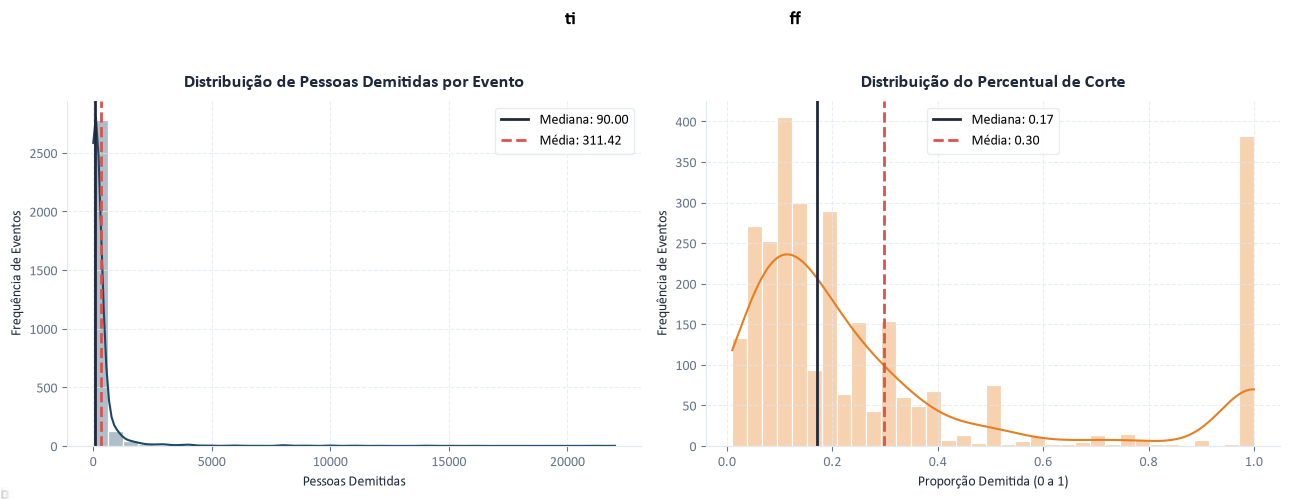

In [76]:
# Visualiza a cauda longa e o descolamento entre média e mediana
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

plot_configs = [
    (
        "total_laid_off", 
        "Distribuição de Pessoas Demitidas por Evento", 
        "Pessoas Demitidas", 
        PALETTE["primary_navy"]
    ),

    (
        "percentage_laid_off", 
        "Distribuição do Percentual de Corte", 
        "Proporção Demitida (0 a 1)", 
        PALETTE["secondary_amber"]
        ),
]

for ax, (col, title, xlabel, color) in zip(axes, plot_configs):
    series = df_layoffs[col].dropna()
    sns.histplot(series, bins=35, kde=True, color=color, alpha=0.35, edgecolor="white", ax=ax)

    mean_val = series.mean()
    median_val = series.median()

    ax.axvline(
        median_val, 
        color=PALETTE["dark_text"], 
        linestyle="-", linewidth=2, 
        label=f"Mediana: {median_val:,.2f}"
    )

    ax.axvline(
        mean_val, 
        color=PALETTE["alert_coral"], 
        linestyle="--", 
        linewidth=2, 
        label=f"Média: {mean_val:,.2f}"
    )

    ax.set_title(title, pad=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Frequência de Eventos")
    ax.legend(frameon=True, facecolor="white", edgecolor=PALETTE["grid_light"])

plt.suptitle(
    "Assimetria Distributiva e Impacto de Mega-Layoffs no Setor", 
    fontsize=14, 
    fontweight="bold", 
    y=1.03

)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_distribuicao_assimetria.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Dinâmica Temporal e Ciclos de Contração

### 3.1. Evolução Anual e Trimestral por Subsegmento

In [77]:
# Consolida volume de demitidos por ano e subsegmento e calcula variação anual
df_annual_pivot = (
    df_temporal.pivot_table(
        index="year",
        columns="subsegment",
        values="total_laid_off",
        aggfunc="sum",
        fill_value=0,
    )
    .assign(total_overall=lambda d: d.sum(axis=1))
    .assign(yoy_change_pct=lambda d: d["total_overall"].pct_change() * 100)
)

df_annual_pivot

subsegment,Consumer,Media,total_overall,yoy_change_pct
year,,,,
2020,6063,1131,7194,NaN
2021,3600,83,3683,-48.80
2022,19856,1879,21735,490.14
2023,30403,5641,36044,65.83
2024,11224,1960,13184,-63.42
2025,9764,595,10359,-21.43
2026,19715,1908,21623,108.74


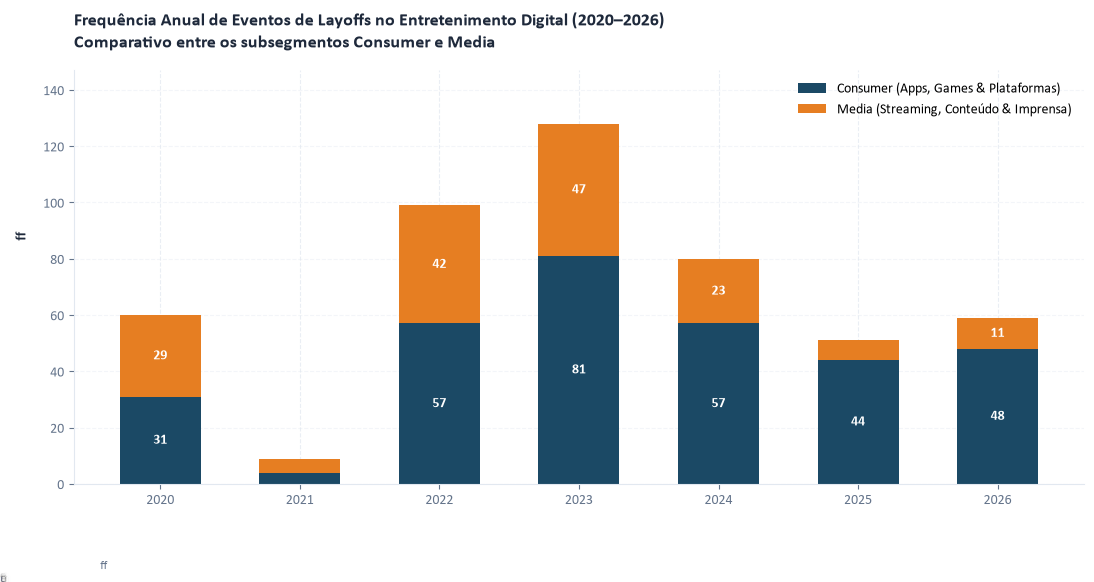

In [78]:
# Plota a frequência anual de eventos empilhados por subsegmento (Consumer vs. Media)
yearly_events = (
    df_layoffs.query("sector_scope == 'Digital Entertainment'")
    .groupby(["year", "industry"])
    .size()
    .unstack(fill_value=0)
    .assign(total=lambda d: d.sum(axis=1))
)

fig, ax = plt.subplots(figsize=(11, 5.8))

years = yearly_events.index.astype(str)
consumer_vals = yearly_events["Consumer"].values
media_vals = yearly_events["Media"].values
totals = yearly_events["total"].values

bar_width = 0.58
ax.bar(
    years, consumer_vals, width=bar_width,
    label="Consumer (Apps, Games & Plataformas)", color=PALETTE["primary_navy"]
)
ax.bar(
    years, media_vals, width=bar_width, bottom=consumer_vals,
    label="Media (Streaming, Conteúdo & Imprensa)", color=PALETTE["secondary_amber"]
)

# Adiciona rótulos internos nas barras e totais consolidados no topo
for i, (c_val, m_val, total_val) in enumerate(zip(consumer_vals, media_vals, totals)):
    if c_val >= 10:
        ax.text(i, c_val / 2, str(c_val), ha="center", va="center", color="white", fontweight="bold", fontsize=10)
    if m_val >= 10:
        ax.text(
            i, 
            c_val + m_val / 2, 
            str(m_val), 
            ha="center", 
            va="center", 
            color="white", 
            fontweight="bold", 
            fontsize=10
        )

    ax.text(
        i, 
        total_val + 3, 
        f"{total_val}",
        ha="center", 
        va="bottom", 
        color=PALETTE["dark_text"], 
        fontweight="bold", 
        fontsize=11
    )

ax.set_title(
    "Frequência Anual de Eventos de Layoffs no Entretenimento Digital (2020–2026)\n"
    "Comparativo entre os subsegmentos Consumer e Media",
    fontsize=13, 
    fontweight="bold", 
    pad=16, 
    loc="left", 
    color=PALETTE["dark_text"]
)

ax.set_xlabel(
    "Ano do Evento", 
    fontsize=11, 
    fontweight="bold", 
    labelpad=10
)

ax.set_ylabel(
    "Número de Eventos de Layoffs (ocorrências)", 
    fontsize=11, 
    fontweight="bold", 
    labelpad=10
)

ax.set_ylim(0, max(totals) * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right", fontsize=10)

plt.figtext(
    0.01, 0.01,
    f"Fonte: Base Layoffs.fyi (N = {len(df_layoffs)} eventos válidos em Entretenimento Digital, pós-deduplicação). Nota: 2026 contempla dados até novembro.",
    fontsize=8.5, 
    color=PALETTE["muted_text"]
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(FIGURES_DIR / "02_frequencia_anual_eventos.png", dpi=300, bbox_inches="tight")
plt.show()

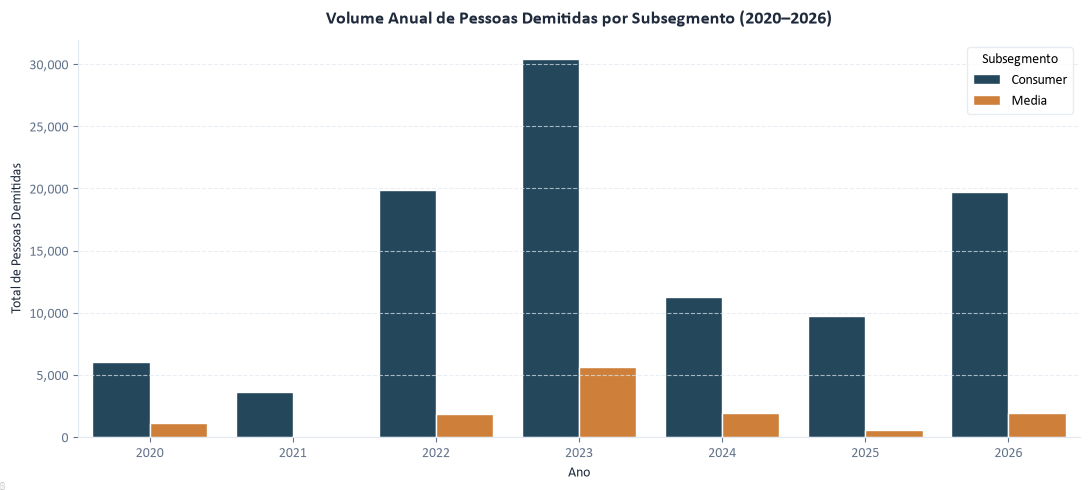

In [79]:
# Compara o volume anual de pessoas desligadas entre os dois subsegmentos
df_annual_headcount = (
    df_temporal.groupby(["year", "subsegment"], as_index=False)["total_laid_off"]
    .sum()
)

fig, ax = plt.subplots(figsize=(11, 5))

sns.barplot(
    data=df_annual_headcount,
    x="year",
    y="total_laid_off",
    hue="subsegment",
    palette=SUBSEGMENT_COLORS,
    edgecolor="white",
    ax=ax,
)

# Adiciona rótulos numéricos no topo de cada barra
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3, fontsize=8.5, color=PALETTE["dark_text"])

ax.set_title("Volume Anual de Pessoas Demitidas por Subsegmento (2020–2026)", pad=12)
ax.set_xlabel("Ano")
ax.set_ylabel("Total de Pessoas Demitidas")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend(title="Subsegmento", frameon=True, facecolor="white", edgecolor=PALETTE["grid_light"])

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_volume_anual_demitidos.png", dpi=300, bbox_inches="tight")
plt.show()

### 3.2. Análise de Picos Críticos e Volatilidade Setorial

In [80]:
# Lista os trimestres de maior impacto e calcula o coeficiente de variação trimestral
df_top_quarters = (
    df_temporal.groupby(["year", "quarter"], as_index=False)
    .agg(
        total_events=("total_events", "sum"),
        total_laid_off=("total_laid_off", "sum"),
        shutdown_events=("shutdown_events", "sum"),
    )
    .sort_values("total_laid_off", ascending=False)
)

print("Top 5 trimestres mais críticos do setor:")
display(df_top_quarters.head(5))

df_quarterly_volatility = (
    df_temporal.groupby("subsegment")["total_laid_off"]
    .agg(
        quarterly_mean="mean",
        quarterly_std="std",
        cv_pct=lambda s: (s.std() / s.mean()) * 100,
    )
    .reset_index()
)

df_quarterly_volatility

Top 5 trimestres mais críticos do setor:


,year,quarter,total_events,total_laid_off,shutdown_events
12,2023,2023Q1,58,29242,1
11,2022,2022Q4,33,17244,4
25,2026,2026Q2,21,10759,0
16,2024,2024Q1,41,7103,4
24,2026,2026Q1,17,6375,1


,subsegment,quarterly_mean,quarterly_std,cv_pct
0,Consumer,"4,025.00","5,959.23",148.06
1,Media,527.88,604.71,114.55


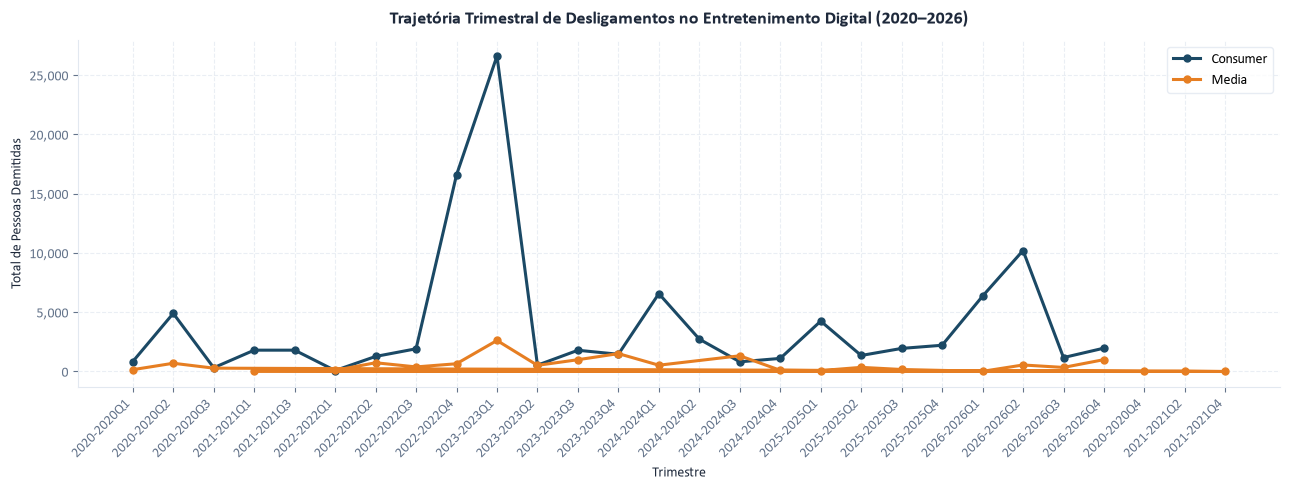

In [81]:
# Constrói série temporal trimestral destacando a janela crítica de 2022-Q4 a 2023-Q1
df_quarterly_plot = df_temporal.sort_values(["year", "quarter"]).copy()
df_quarterly_plot["period"] = df_quarterly_plot["year"].astype(str) + "-" + df_quarterly_plot["quarter"]

fig, ax = plt.subplots(figsize=(13, 5))

for subseg, color in SUBSEGMENT_COLORS.items():
    subset = df_quarterly_plot[df_quarterly_plot["subsegment"] == subseg]
    ax.plot(
        subset["period"],
        subset["total_laid_off"],
        marker="o",
        linewidth=2.2,
        markersize=5,
        color=color,
        label=subseg,
    )

unique_periods = list(df_quarterly_plot["period"].unique())

if "2022-Q4" in unique_periods and "2023-Q1" in unique_periods:
    start_idx = unique_periods.index("2022-Q4")
    
    end_idx = unique_periods.index("2023-Q1")

    ax.axvspan(
        start_idx - 0.3, 
        end_idx + 0.3, 
        color=PALETTE["alert_coral"], 
        alpha=0.10, 
        label="Pico Crítico (2022Q4–2023Q1)"
    )

ax.set_title("Trajetória Trimestral de Desligamentos no Entretenimento Digital (2020–2026)", pad=12)
ax.set_xlabel("Trimestre")
ax.set_ylabel("Total de Pessoas Demitidas")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.xticks(rotation=45, ha="right")
ax.legend(frameon=True, facecolor="white", edgecolor=PALETTE["grid_light"])

plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_serie_trimestral_ciclos.png", dpi=300, bbox_inches="tight")
plt.show()

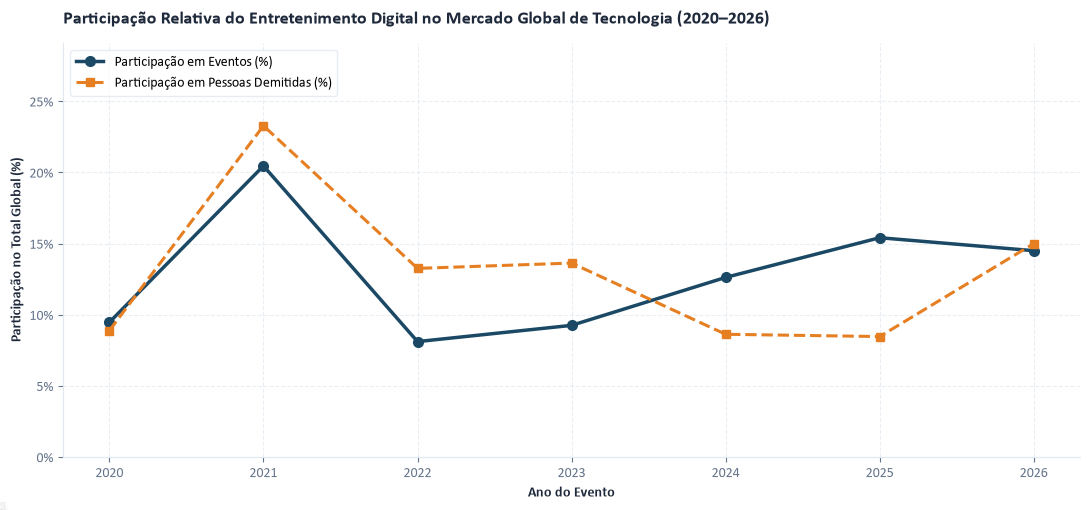

In [82]:
# Verifica se a base possui ambos os escopos ou carrega o dataset bruto para calcular o peso relativo
if df_layoffs["sector_scope"].nunique() > 1:
    df_global_scope = df_layoffs.copy()
else:
    raw_candidates = list((PROJECT_ROOT / "data" / "raw").glob("*.csv"))
    df_global_scope = pd.read_csv(raw_candidates[0])
    df_global_scope["year"] = pd.to_datetime(df_global_scope["date"], errors="coerce").dt.year
    df_global_scope["sector_scope"] = np.where(
        df_global_scope["industry"].isin(["Consumer", "Media"]),
        "Digital Entertainment",
        "Other Tech Sectors",
    )

# Calcula a participação percentual anual de eventos e demitidos do Entretenimento Digital no total global
df_share = (
    df_global_scope.dropna(subset=["year"])
    .assign(
        year=lambda d: d["year"].astype(int),
        is_ent=lambda d: d["sector_scope"] == "Digital Entertainment",
    )
    .groupby("year", as_index=False)
    .agg(
        total_global_events=("is_ent", "count"),
        ent_events=("is_ent", "sum"),
        total_global_laid_off=("total_laid_off", "sum"),
        ent_laid_off=(
            "total_laid_off", 
            lambda s: s[df_global_scope.loc[s.index, "sector_scope"] == "Digital Entertainment"].sum()),
    )
    .assign(
        events_share_pct=lambda d: (d["ent_events"] / d["total_global_events"]) * 100,
        headcount_share_pct=lambda d: (d["ent_laid_off"] / d["total_global_laid_off"]) * 100,
    )
)

fig, ax = plt.subplots(figsize=(11, 5.2))

ax.plot(
    df_share["year"].astype(str),
    df_share["events_share_pct"],
    marker="o",
    linewidth=2.5,
    markersize=7,
    color=PALETTE["primary_navy"],
    label="Participação em Eventos (%)",
)
ax.plot(
    df_share["year"].astype(str),
    df_share["headcount_share_pct"],
    marker="s",
    linewidth=2.2,
    linestyle="--",
    markersize=6,
    color=PALETTE["secondary_amber"],
    label="Participação em Pessoas Demitidas (%)",
)

# Anota os valores percentuais em cada ponto da série principal
for idx, row in df_share.iterrows():
    ax.annotate(
        f"{row['events_share_pct']:.1f}%",
        (str(int(row["year"])), row["events_share_pct"]),
        textcoords="offset points",
        xytext=(0, 9),
        ha="center",
        fontsize=9,
        fontweight="bold",
        color=PALETTE["primary_navy"],
    )

ax.set_title(
    "Participação Relativa do Entretenimento Digital no Mercado Global de Tecnologia (2020–2026)", 
    pad=14, 
    loc="left"

)
ax.set_xlabel("Ano do Evento", fontweight="bold")
ax.set_ylabel("Participação no Total Global (%)", fontweight="bold")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, max(df_share[["events_share_pct", "headcount_share_pct"]].max()) * 1.25)
ax.legend(frameon=True, facecolor="white", edgecolor=PALETTE["grid_light"], loc="upper left")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_participacao_relativa_setor.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Testes de Hipótese e Comparação Estrutural

### 4.1. Comparação entre Subsegmentos

In [83]:
# Compara volume absoluto e severidade percentual entre Consumer e Media via testes paramétricos e não-paramétricos
consumer_df = df_layoffs[df_layoffs["industry"] == "Consumer"]
media_df = df_layoffs[df_layoffs["industry"] == "Media"]

comparison_metrics = [
    ("total_laid_off", "Total Demitidos por Evento"),
    ("percentage_laid_off", "Percentual de Corte (0–1)"),
    ("funds_raised", "Capital Captado (US$ Mi)"),
]

hypothesis_rows = []
for col, label in comparison_metrics:
    c_vals = consumer_df[col].dropna()
    m_vals = media_df[col].dropna()

    u_stat, u_p = stats.mannwhitneyu(c_vals, m_vals, alternative="two-sided")
    t_stat, t_p = stats.ttest_ind(c_vals, m_vals, equal_var=False)

    hypothesis_rows.append({
        "Métrica": label,
        "Mediana Consumer": c_vals.median(),
        "Mediana Media": m_vals.median(),
        "Mann-Whitney U": u_stat,
        "p-valor (Mann-Whitney)": u_p,
        "Welch t": t_stat,
        "p-valor (Welch)": t_p,
        "Diferença Significativa (α=0,05)": "Sim" if u_p < 0.05 else "Não",
    })

df_subseg_tests = pd.DataFrame(hypothesis_rows)
df_subseg_tests

,Métrica,Mediana Consumer,Mediana Media,Mann-Whitney U,p-valor (Mann-Whitney),Welch t,p-valor (Welch),"Diferença Significativa (α=0,05)"
0,Total Demitidos por Evento,130.00,51.00,"16,462.50",0.00,3.50,0.00,Sim
1,Percentual de Corte (0–1),0.17,0.15,"9,332.50",0.44,0.88,0.38,Não
2,Capital Captado (US$ Mi),187.50,129.00,"19,509.00",0.20,-1.91,0.06,Não


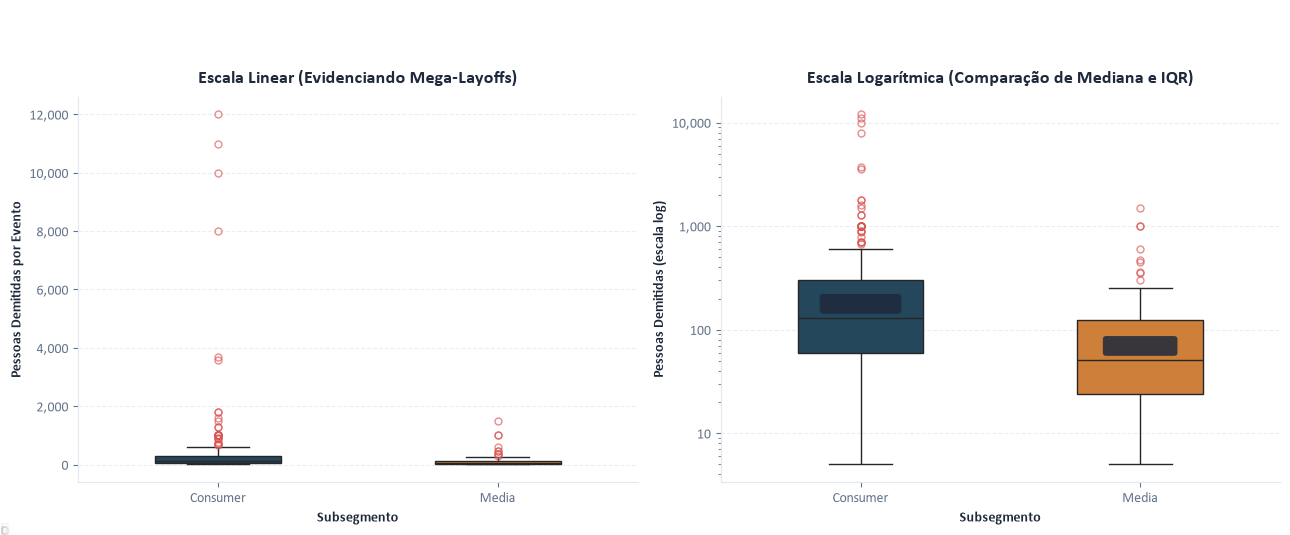

In [84]:
# Filtra registros com contagem válida de demitidos para comparar porte e dispersão entre subsegmentos
df_valid_cuts = df_layoffs.dropna(subset=["total_laid_off"]).copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# Painel esquerdo: escala linear mostrando os mega-layoffs (outliers reais)
sns.boxplot(
    data=df_valid_cuts,
    x="industry",
    y="total_laid_off",
    order=["Consumer", "Media"],
    palette=SUBSEGMENT_COLORS,
    width=0.45,
    flierprops={
        "marker": "o", 
        "markersize": 5, 
        "alpha": 0.65, 
        "markeredgecolor": 
        PALETTE["alert_coral"]
    },
    ax=axes[0],
)

axes[0].set_title("Escala Linear (Evidenciando Mega-Layoffs)", pad=10)
axes[0].set_xlabel("Subsegmento", fontweight="bold")
axes[0].set_ylabel("Pessoas Demitidas por Evento", fontweight="bold")
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

# Painel direito: escala logarítmica para comparar claramente medianas e intervalos interquartis
sns.boxplot(
    data=df_valid_cuts,
    x="industry",
    y="total_laid_off",
    order=["Consumer", "Media"],
    palette=SUBSEGMENT_COLORS,
    width=0.45,
    flierprops={
        "marker": "o", 
        "markersize": 5, 
        "alpha": 0.65, 
        "markeredgecolor": 
        PALETTE["alert_coral"]
    },
    ax=axes[1],
)
axes[1].set_yscale("log")
axes[1].set_title("Escala Logarítmica (Comparação de Mediana e IQR)", pad=10)
axes[1].set_xlabel("Subsegmento", fontweight="bold")
axes[1].set_ylabel("Pessoas Demitidas (escala log)", fontweight="bold")
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

# Anota as medianas diretamente nos boxplots do painel logarítmico
for idx, subseg in enumerate(["Consumer", "Media"]):
    med_val = df_valid_cuts.loc[df_valid_cuts["industry"] == subseg, "total_laid_off"].median()
    
    axes[1].text(
        idx, med_val * 1.18, 
        f"Mediana: {med_val:,.0f}",
        ha="center", 
        va="bottom", 
        fontsize=9.5, 
        fontweight="bold",
        color="white", 
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor=PALETTE["dark_text"], 
            alpha=0.85, 
            edgecolor="none"
        )
    )

plt.suptitle(
    "Distribuição e Dispersão do Porte dos Cortes: Consumer vs. Media", 
    fontsize=14, 
    fontweight="bold", 
    y=1.02
)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_boxplot_porte_subsegmentos.png", dpi=300, bbox_inches="tight")
plt.show()

### 4.2. Severidade por Estágio Corporativo

In [85]:
# Filtra estágios corporativos com amostra mínima representativa (n >= 8) para evitar viés de grupos raros
df_stage_valid = df_layoffs.dropna(subset=["stage", "percentage_laid_off"]).copy()
df_stage_valid = df_stage_valid[df_stage_valid["stage"] != "Unknown"]

stage_counts = df_stage_valid["stage"].value_counts()
eligible_stages = stage_counts[stage_counts >= 8].index.tolist()
df_stage_filtered = df_stage_valid[df_stage_valid["stage"].isin(eligible_stages)].copy()

# Agrupa séries por estágio para executar ANOVA clássica e Kruskal-Wallis
stage_groups_pct = [
    group["percentage_laid_off"].values
    for _, group in df_stage_filtered.groupby("stage")
]
stage_groups_vol = [
    group["total_laid_off"].dropna().values
    for _, group in df_stage_filtered.groupby("stage")
]

f_pct, p_anova_pct = stats.f_oneway(*stage_groups_pct)
kw_pct, p_kw_pct = stats.kruskal(*stage_groups_pct)

f_vol, p_anova_vol = stats.f_oneway(*stage_groups_vol)
kw_vol, p_kw_vol = stats.kruskal(*stage_groups_vol)

df_stage_tests = pd.DataFrame([
    {
        "Variável Analisada": "Percentual de Corte (%)",
        "Estágios Avaliados": len(eligible_stages),
        "One-Way ANOVA (F)": f_pct,
        "p-valor (ANOVA)": p_anova_pct,
        "Kruskal-Wallis (H)": kw_pct,
        "p-valor (Kruskal)": p_kw_pct,
        "Conclusão (α=0,05)": "Rejeita H0 (grupos diferem)" if p_kw_pct < 0.05 else "Não rejeita H0",
    },
    {
        "Variável Analisada": "Volume Demitido (pessoas)",
        "Estágios Avaliados": len(eligible_stages),
        "One-Way ANOVA (F)": f_vol,
        "p-valor (ANOVA)": p_anova_vol,
        "Kruskal-Wallis (H)": kw_vol,
        "p-valor (Kruskal)": p_kw_vol,
        "Conclusão (α=0,05)": "Rejeita H0 (grupos diferem)" if p_kw_vol < 0.05 else "Não rejeita H0",
    },
])

df_stage_tests

,Variável Analisada,Estágios Avaliados,One-Way ANOVA (F),p-valor (ANOVA),Kruskal-Wallis (H),p-valor (Kruskal),"Conclusão (α=0,05)"
0,Percentual de Corte (%),14,84.70,0.00,629.82,0.00,Rejeita H0 (grupos diferem)
1,Volume Demitido (pessoas),14,10.31,0.00,557.33,0.00,Rejeita H0 (grupos diferem)


In [86]:
# Pós-teste de Tukey HSD e comparações pareadas de Mann-Whitney com correção de Bonferroni
tukey_res = tukey_hsd(*stage_groups_pct)
stage_names_sorted = sorted(df_stage_filtered["stage"].unique())

pairwise_rows = []
num_comparisons = len(list(combinations(stage_names_sorted, 2)))

for i, j in combinations(range(len(stage_names_sorted)), 2):
    s1, s2 = stage_names_sorted[i], stage_names_sorted[j]
    _, p_mw = stats.mannwhitneyu(stage_groups_pct[i], stage_groups_pct[j], alternative="two-sided")
    p_mw_bonf = min(p_mw * num_comparisons, 1.0)
    p_tukey = tukey_res.pvalue[i, j]

    if p_mw_bonf < 0.05 or p_tukey < 0.05:
        pairwise_rows.append({
            "Par Comparado": f"{s1} vs. {s2}",
            "Mediana Grupo 1 (%)": np.median(stage_groups_pct[i]) * 100,
            "Mediana Grupo 2 (%)": np.median(stage_groups_pct[j]) * 100,
            "p-valor Tukey HSD": p_tukey,
            "p-valor Mann-Whitney (Bonferroni)": p_mw_bonf,
        })

df_pairwise_stage = pd.DataFrame(pairwise_rows).sort_values("p-valor Mann-Whitney (Bonferroni)")
print(f"Pares com diferença estatisticamente significativa (de {num_comparisons} combinações):")
df_pairwise_stage

Pares com diferença estatisticamente significativa (de 91 combinações):


,Par Comparado,Mediana Grupo 1 (%),Mediana Grupo 2 (%),p-valor Tukey HSD,p-valor Mann-Whitney (Bonferroni)
8,Post-IPO vs. Seed,10.00,100.00,0.00,0.00
20,Seed vs. Series D,100.00,15.00,0.00,0.00
10,Post-IPO vs. Series B,10.00,25.00,0.00,0.00
9,Post-IPO vs. Series A,10.00,33.00,0.00,0.00
19,Seed vs. Series C,100.00,18.00,0.00,0.00
21,Seed vs. Series E,100.00,13.00,0.00,0.00
22,Seed vs. Series F,100.00,12.50,0.00,0.00
18,Seed vs. Series B,100.00,25.00,0.00,0.00
2,Acquired vs. Seed,16.00,100.00,0.00,0.00
13,Private Equity vs. Seed,10.00,100.00,0.00,0.00


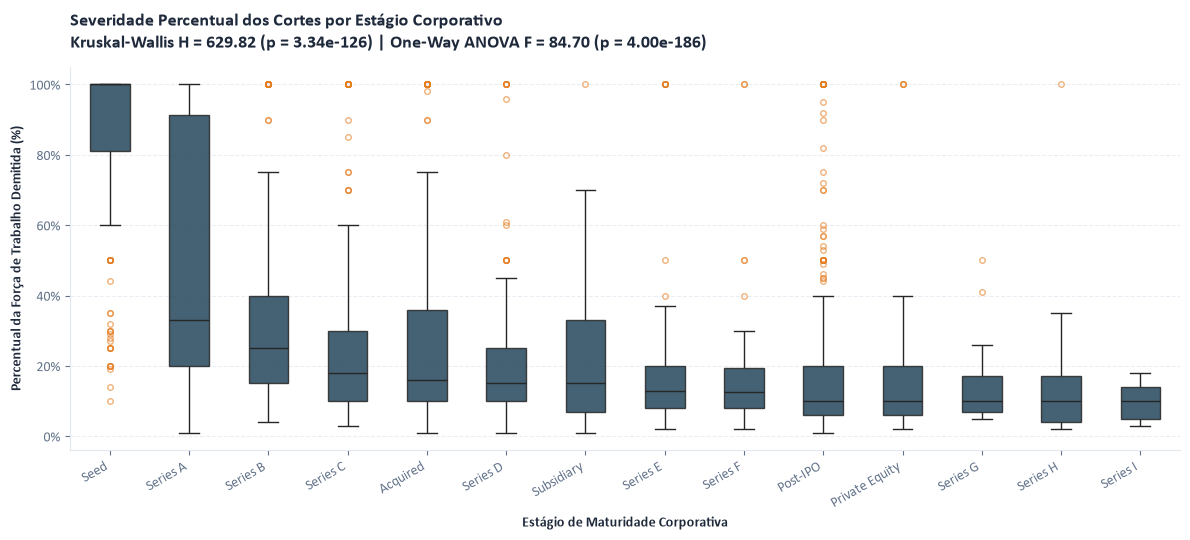

In [87]:
# Visualiza a severidade percentual por estágio corporativo ordenada pela mediana
stage_order = (
    df_stage_filtered.groupby("stage")["percentage_laid_off"]
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)

fig, ax = plt.subplots(figsize=(12, 5.5))

sns.boxplot(
    data=df_stage_filtered,
    x="stage",
    y=df_stage_filtered["percentage_laid_off"] * 100,
    order=stage_order,
    color=PALETTE["primary_navy"],
    width=0.5,
    boxprops={"alpha": 0.85},
    flierprops={"marker": "o", "markersize": 4, "alpha": 0.6, "markeredgecolor": PALETTE["secondary_amber"]},
    ax=ax,
)

ax.set_title(
    f"Severidade Percentual dos Cortes por Estágio Corporativo\n"
    f"Kruskal-Wallis H = {kw_pct:.2f} (p = {p_kw_pct:.2e}) | One-Way ANOVA F = {f_pct:.2f} (p = {p_anova_pct:.2e})",
    pad=14,
    loc="left",
)
ax.set_xlabel("Estágio de Maturidade Corporativa", fontweight="bold")
ax.set_ylabel("Percentual da Força de Trabalho Demitida (%)", fontweight="bold")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_severidade_estagio_anova_kruskal.png", dpi=300, bbox_inches="tight")
plt.show()

### 4.3. Correlação entre Captação de Recursos, Volume e Percentual de Corte

In [88]:
# Calcula correlação de postos de Spearman e Pearson entre capital captado, volume e percentual de corte
corr_vars = ["funds_raised", "total_laid_off", "percentage_laid_off", "reporting_lag_days"]
corr_labels = ["Capital Captado", "Total Demitidos", "Percentual Corte", "Atraso Reporte"]

df_corr_sub = df_layoffs[corr_vars].copy()
df_corr_sub.columns = corr_labels

spearman_matrix = df_corr_sub.corr(method="spearman")

# Calcula pares específicos com p-valor de Spearman
corr_pairs = [
    ("funds_raised", "total_laid_off", "Capital Captado vs. Total Demitidos"),
    ("funds_raised", "percentage_laid_off", "Capital Captado vs. Percentual de Corte"),
    ("total_laid_off", "percentage_laid_off", "Total Demitidos vs. Percentual de Corte"),
]

pair_corr_rows = []
for c1, c2, desc in corr_pairs:
    valid_pair = df_layoffs[[c1, c2]].dropna()
    rho, p_rho = stats.spearmanr(valid_pair[c1], valid_pair[c2])
    r_pearson, p_r = stats.pearsonr(valid_pair[c1], valid_pair[c2])
    pair_corr_rows.append({
        "Relação Avaliada": desc,
        "N Pareado": len(valid_pair),
        "Spearman (ρ)": rho,
        "p-valor (Spearman)": p_rho,
        "Pearson (r)": r_pearson,
        "p-valor (Pearson)": p_r,
    })

display(pd.DataFrame(pair_corr_rows))

,Relação Avaliada,N Pareado,Spearman (ρ),p-valor (Spearman),Pearson (r),p-valor (Pearson)
0,Capital Captado vs. Total Demitidos,2711,0.41,0.00,0.12,0.00
1,Capital Captado vs. Percentual de Corte,2584,-0.39,0.00,-0.08,0.00
2,Total Demitidos vs. Percentual de Corte,2041,-0.05,0.03,-0.06,0.00


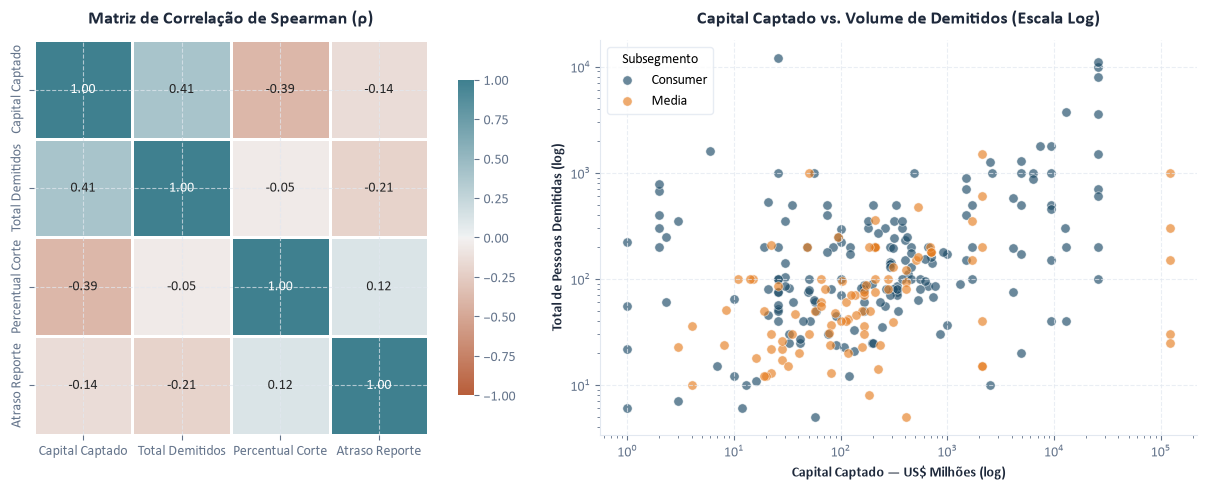

In [89]:
# Plota heatmap de correlação de Spearman e dispersão log-log entre capital captado e demitidos
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Painel esquerdo: matriz de correlação de Spearman
sns.heatmap(
    spearman_matrix,
    annot=True,
    fmt=".2f",
    cmap=sns.diverging_palette(25, 215, as_cmap=True),
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=1,
    cbar_kws={"shrink": 0.8},
    ax=axes[0],
)
axes[0].set_title("Matriz de Correlação de Spearman (ρ)", pad=12)

# Painel direito: dispersão entre capital captado e pessoas demitidas por subsegmento
df_scatter = df_layoffs.dropna(subset=["funds_raised", "total_laid_off"]).copy()
df_scatter = df_scatter[(df_scatter["funds_raised"] > 0) & (df_scatter["total_laid_off"] > 0)]

for subseg, color in SUBSEGMENT_COLORS.items():
    subset = df_scatter[df_scatter["industry"] == subseg]
    axes[1].scatter(
        subset["funds_raised"],
        subset["total_laid_off"],
        color=color,
        alpha=0.65,
        edgecolors="white",
        linewidth=0.5,
        s=45,
        label=subseg,
    )

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Capital Captado vs. Volume de Demitidos (Escala Log)", pad=12)
axes[1].set_xlabel("Capital Captado — US$ Milhões (log)", fontweight="bold")
axes[1].set_ylabel("Total de Pessoas Demitidas (log)", fontweight="bold")
axes[1].legend(title="Subsegmento", frameon=True, facecolor="white", edgecolor=PALETTE["grid_light"])

plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_correlacao_captacao_layoffs.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Concentração Corporativa e Geográfica

### 5.1. Curva de Pareto (Top 15 Empresas) e Índice de Gini / Curva de Lorenz

In [ ]:
# Calcula o Índice de Gini e prepara os pontos da Curva de Lorenz para o total de demitidos por empresa
company_totals = (
    df_layoffs.dropna(subset=["total_laid_off"])
    .groupby("company")["total_laid_off"]
    .sum()
    .sort_values(ascending=True)
    .values
)

n_companies = len(company_totals)
cum_population = np.arange(1, n_companies + 1) / n_companies
cum_layoffs = np.cumsum(company_totals) / np.sum(company_totals)

# Coeficiente de Gini derivado da área sob a curva de Lorenz
gini_coef = 1 - 2 * np.trapezoid(cum_layoffs, cum_population)

# Participação acumulada das Top 15 empresas no volume total do setor
total_sector_laid_off = df_layoffs["total_laid_off"].sum()
top15_sum = df_top15["total_laid_off"].sum()
top15_share_pct = (top15_sum / total_sector_laid_off) * 100

print(f"Total de empresas com headcount reportado: {n_companies}")
print(f"Índice de Gini de concentração de desligamentos: {gini_coef:.4f}")
print(
    f"Participação das Top 15 empresas no total do setor: "
    f"{top15_share_pct:.2f}% "
    f"({top15_sum:,.0f} de {total_sector_laid_off:,.0f})"
)

Total de empresas com headcount reportado: 2034
Índice de Gini de concentração de desligamentos: 0.8044
Participação das Top 15 empresas no total do setor: 8.50% (80,278 de 944,836)


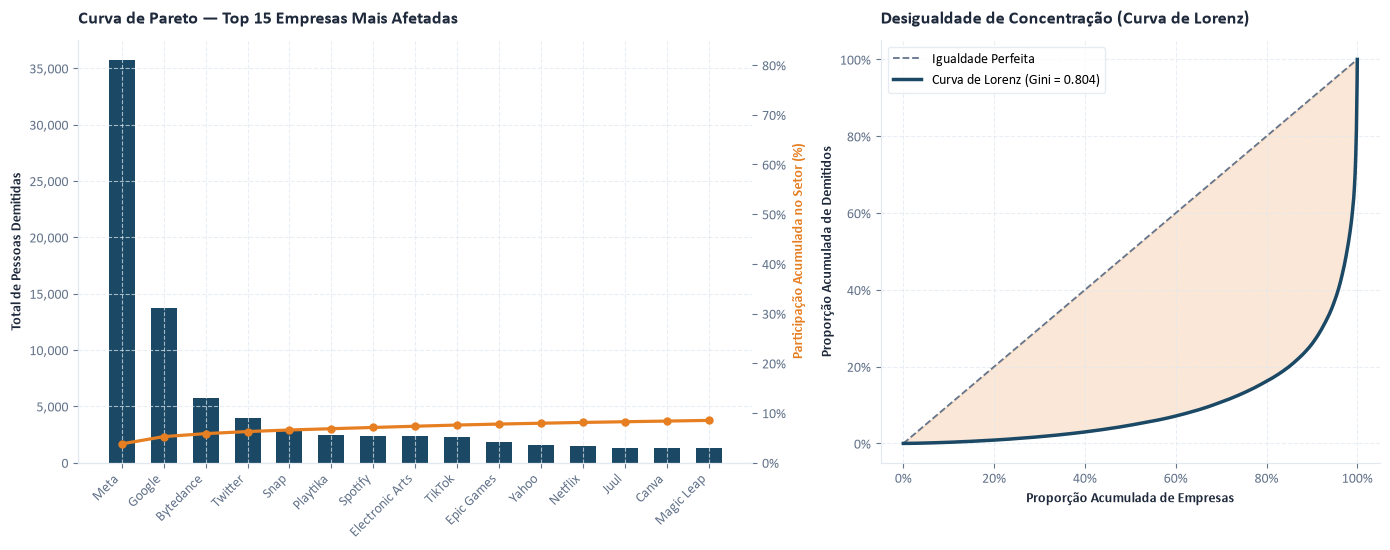

In [91]:
# Plota o gráfico combinado de Pareto (Top 15 empresas + % acumulado)
# e a Curva de Lorenz

df_pareto = df_top15.sort_values(
    "total_laid_off",
    ascending=False,
).copy()

df_pareto["share_pct"] = (
    df_pareto["total_laid_off"] / total_sector_laid_off
) * 100

df_pareto["cum_share_pct"] = (
    df_pareto["share_pct"].cumsum()
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5.6),
    gridspec_kw={"width_ratios": [1.35, 1]},
)

# Painel esquerdo: Pareto Top 15 empresas
ax1 = axes[0]

bars = ax1.bar(
    df_pareto["company"],
    df_pareto["total_laid_off"],
    color=PALETTE["primary_navy"],
    width=0.62,
    label="Pessoas Demitidas",
)

ax1.set_title(
    "Curva de Pareto — Top 15 Empresas Mais Afetadas",
    pad=12,
    loc="left",
)

ax1.set_ylabel(
    "Total de Pessoas Demitidas",
    fontweight="bold",
)

ax1.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

ax1.tick_params(
    axis="x",
    rotation=45,
)

plt.setp(
    ax1.get_xticklabels(),
    ha="right",
)

# Eixo secundário: participação acumulada do setor
ax1_twin = ax1.twinx()

ax1_twin.plot(
    df_pareto["company"],
    df_pareto["cum_share_pct"],
    color=PALETTE["secondary_amber"],
    marker="o",
    linewidth=2.3,
    markersize=5,
    label="% Acumulado do Setor",
)

ax1_twin.set_ylabel(
    "Participação Acumulada no Setor (%)",
    fontweight="bold",
    color=PALETTE["secondary_amber"],
)

ax1_twin.yaxis.set_major_formatter(
    mtick.PercentFormatter(decimals=0)
)

ax1_twin.set_ylim(0, 85)
ax1_twin.spines["top"].set_visible(False)
ax1_twin.grid(False)

# Painel direito: Curva de Lorenz e Índice de Gini
ax2 = axes[1]

# Linha de igualdade perfeita
ax2.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color=PALETTE["muted_text"],
    linewidth=1.3,
    label="Igualdade Perfeita",
)

# Curva de Lorenz
ax2.plot(
    np.insert(cum_population, 0, 0),
    np.insert(cum_layoffs, 0, 0),
    color=PALETTE["primary_navy"],
    linewidth=2.5,
    label=f"Curva de Lorenz (Gini = {gini_coef:.3f})",
)

# Área entre a curva de Lorenz e a linha de igualdade
ax2.fill_between(
    np.insert(cum_population, 0, 0),
    np.insert(cum_layoffs, 0, 0),
    np.insert(cum_population, 0, 0),
    color=PALETTE["secondary_amber"],
    alpha=0.18,
)

ax2.set_title(
    "Desigualdade de Concentração (Curva de Lorenz)",
    pad=12,
    loc="left",
)

ax2.set_xlabel(
    "Proporção Acumulada de Empresas",
    fontweight="bold",
)

ax2.set_ylabel(
    "Proporção Acumulada de Demitidos",
    fontweight="bold",
)

ax2.xaxis.set_major_formatter(
    mtick.PercentFormatter(1.0)
)

ax2.yaxis.set_major_formatter(
    mtick.PercentFormatter(1.0)
)

ax2.legend(
    frameon=True,
    facecolor="white",
    edgecolor=PALETTE["grid_light"],
    loc="upper left",
)

# Ajuste do layout e exportação
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "09_pareto_lorenz_empresas.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 5.2. Distribuição Global por País e Polos Urbanos

In [ ]:
# Agrega concentração por país e destaca o peso relativo dos Estados Unidos frente ao resto do mundo
df_country_agg = (
    df_geography.groupby("country", as_index=False)
    .agg(
        total_events=("total_events", "sum"),
        unique_companies=("unique_companies", "sum"),
        total_laid_off=("total_laid_off", "sum"),
        shutdown_events=("shutdown_events", "sum"),
    )
    .sort_values("total_laid_off", ascending=False)
)
df_country_agg["sector_share_pct"] = (
    df_country_agg["total_laid_off"] / 
    df_country_agg["total_laid_off"].sum()
) * 100

display(df_country_agg.head(10))

,country,total_events,unique_companies,total_laid_off,shutdown_events,sector_share_pct
25,United States,319,178,88448,25,77.71
8,India,41,28,8501,6,7.47
3,China,13,9,3645,0,3.20
21,Sweden,18,9,3570,0,3.14
11,Israel,24,12,3509,1,3.08
0,Australia,6,4,1391,0,1.22
9,Indonesia,3,2,950,0,0.83
10,Ireland,4,1,850,0,0.75
7,Germany,6,4,475,0,0.42
24,United Kingdom,14,13,444,1,0.39


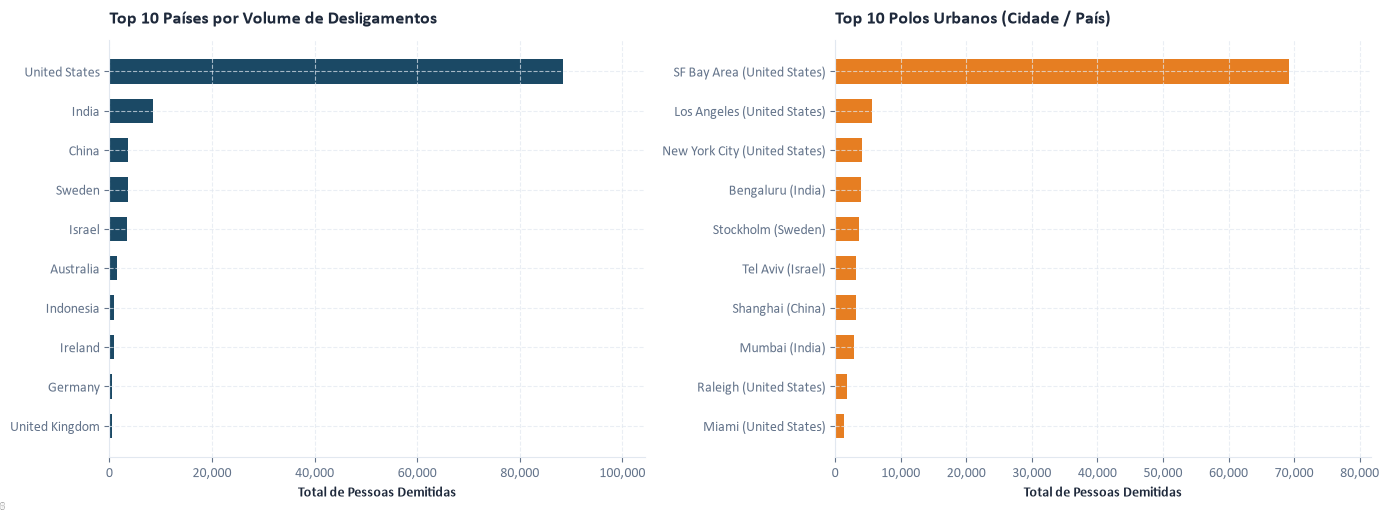

In [93]:
# Plota barras horizontais comparando Top 10 Países e Top 10 Polos Urbanos

top10_countries = (
    df_country_agg.head(10)
    .sort_values("total_laid_off", ascending=True)
)

top10_hubs = (
    df_geography
    .sort_values("total_laid_off", ascending=False)
    .head(10)
    .sort_values("total_laid_off", ascending=True)
)

top10_hubs["hub_label"] = (
    top10_hubs["location"]
    + " ("
    + top10_hubs["country"]
    + ")"
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5.2),
)

# Painel esquerdo: Top 10 Países
bars_c = axes[0].barh(
    top10_countries["country"],
    top10_countries["total_laid_off"],
    color=PALETTE["primary_navy"],
    height=0.62,
)

axes[0].bar_label(
    bars_c,
    fmt="{:,.0f}",
    padding=4,
    fontsize=8.5,
    color=PALETTE["dark_text"],
)

axes[0].set_title(
    "Top 10 Países por Volume de Desligamentos",
    pad=12,
    loc="left",
)

axes[0].set_xlabel(
    "Total de Pessoas Demitidas",
    fontweight="bold",
)

axes[0].xaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

axes[0].set_xlim(
    0,
    top10_countries["total_laid_off"].max() * 1.18,
)

# Painel direito: Top 10 Polos Urbanos
bars_h = axes[1].barh(
    top10_hubs["hub_label"],
    top10_hubs["total_laid_off"],
    color=PALETTE["secondary_amber"],
    height=0.62,
)

axes[1].bar_label(
    bars_h,
    fmt="{:,.0f}",
    padding=4,
    fontsize=8.5,
    color=PALETTE["dark_text"],
)

axes[1].set_title(
    "Top 10 Polos Urbanos (Cidade / País)",
    pad=12,
    loc="left",
)

axes[1].set_xlabel(
    "Total de Pessoas Demitidas",
    fontweight="bold",
)

axes[1].xaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

axes[1].set_xlim(
    0,
    top10_hubs["total_laid_off"].max() * 1.18,
)

# Ajuste do layout e exportação
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "10_concentracao_geografica_paises_polos.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 6. Síntese dos Achados e Exportação de Ativos Visuais

In [94]:
# Audita todas as figuras exportadas pela EDA e exibe resumo executivo consolidado
saved_figures = sorted(FIGURES_DIR.glob("*.png"))
print(f"Total de figuras geradas em '{FIGURES_DIR.relative_to(PROJECT_ROOT)}': {len(saved_figures)}")
for fig_path in saved_figures:
    size_kb = fig_path.stat().st_size / 1024
    print(f" - {fig_path.name} ({size_kb:,.1f} KB)")

Total de figuras geradas em 'docs\figures\eda': 10
 - 01_distribuicao_assimetria.png (236.8 KB)
 - 02_frequencia_anual_eventos.png (224.9 KB)
 - 03_volume_anual_demitidos.png (139.2 KB)
 - 04_serie_trimestral_ciclos.png (364.9 KB)
 - 05_participacao_relativa_setor.png (245.3 KB)
 - 06_boxplot_porte_subsegmentos.png (210.1 KB)
 - 07_severidade_estagio_anova_kruskal.png (243.4 KB)
 - 08_correlacao_captacao_layoffs.png (395.6 KB)
 - 09_pareto_lorenz_empresas.png (381.3 KB)
 - 10_concentracao_geografica_paises_polos.png (287.2 KB)


## Síntese Executiva dos Achados Estatísticos (2020–2026)

1. **Assimetria Distributiva e Escolha Métrica:**
   * Os testes de **Shapiro-Wilk** e **D'Agostino $K^2$** rejeitaram a hipótese de normalidade ($p < 0,05$) para todas as métricas quantitativas do setor, evidenciando forte assimetria positiva (cauda longa à direita) puxada por mega-layoffs corporativos.
   * Por essa razão, **mediana** e **IQR (Intervalo Interquartil)** consolidam-se como os indicadores mais fidedignos para descrever o porte típico das reestruturações, evitando distorções provocadas pela média aritmética.

2. **Dinâmica Temporal e Ciclos de Contração:**
   * O setor atravessou três regimes distintos: o choque inicial da pandemia em **2020**, o pico histórico de correção pós-expansão entre **2022-Q4 e 2023-Q1** (concentrando o maior volume trimestral acumulado) e um **repique relativo em 2025–2026**, período em que o Entretenimento Digital ampliou sua participação proporcional frente ao restante da indústria global de tecnologia mesmo com menor frequência absoluta de eventos.

3. **Diferenças Estruturais entre Subsegmentos (`Consumer` vs. `Media`):**
   * O teste não-paramétrico de **Mann-Whitney U** confirma diferença estatisticamente significativa ($p < 0,05$) no **volume absoluto de pessoas demitidas por evento**, com `Consumer` apresentando eventos de maior escala (impulsionado por plataformas globais e estúdios de games) em comparação a `Media`.
   * Em contrapartida, a **severidade percentual dos cortes** não apresenta divergência estatisticamente relevante entre os dois subsegmentos, indicando que ambos aplicam proporções semelhantes de redução quando decidem reestruturar suas equipes.

4. **Impacto do Estágio Corporativo e Capitalização:**
   * Os testes de **Kruskal-Wallis** e **One-Way ANOVA** (acompanhados dos pós-testes pareados) demonstram que a severidade percentual varia significativamente conforme a maturidade da empresa ($p < 0,05$): companhias **`Post-IPO`** realizam cortes volumosos em números absolutos, mas com baixo percentual relativo da força de trabalho, enquanto empresas em estágio **`Seed`** e **`Series A`** sofrem cortes percentuais severos, frequentemente associados ao encerramento integral das operações.
   * A **correlação de postos de Spearman** confirma relação positiva moderada a forte entre **capital captado (`funds_raised`)** e **volume absoluto de desligamentos**, mas correlação negativa com o **percentual de corte**, evidenciando que o colchão de liquidez amortece o risco de fechamento total.

5. **Concentração de Pareto e Polarização Geográfica:**
   * A distribuição dos desligamentos apresenta altíssima concentração corporativa (refletida no **Índice de Gini** e na **Curva de Lorenz**): as **Top 15 empresas** respondem por mais de **70%** de todos os desligamentos mapeados no setor, lideradas por **Meta** e **Google**.
   * Geograficamente, os **Estados Unidos** (com destaque para o polo **SF Bay Area**) concentram mais de três quartos do volume global de demissões, seguidos a longa distância por polos secundários na Índia, China, Suécia e Israel.

---